# Pittsburgh Facilities: Number of Facilities by Neighborhood
## Aurora's metric

### Introduction
For my individual metric, I will investigate the number of facilities in each neighborhood. I want to compare these metrics to to determine which areas generally have the best amenities**Aurora's Metric**

### Metric
My individual metric is the number of **facilities** in each Pittsburgh neighborhood. “Facilities” includes police stations, firehouses, public pools, parks, shelters, recreation centers, courts and fields, and senior centers. I will compare the number of facilities to determine the socio-economic environment in each neighborhood.


### Dataset
I will use the [City of Pittsburgh Facilities dataset](https://data.wprdc.org/dataset/city-of-pittsburgh-facilities) from the Western Pennsylvania Regional Data Center (WPRDC).

This dataset contains the number of Pittsburgh facilities collected by the Operations Management System for the Department of Public Works. It includes information such as facility names, addresses, whether or not they are rentable, and the neighborhoods they are located in. I will use these metrics to compare the socio-economic environment of different locations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt'Data/Neighborhoods.csv')
neighborhoods = df['hood'].dropna().unique().tolist()

In [2]:
df = pd.read_csv('Data/Neighborhoods.csv')
neighborhoods = df['hood'].dropna().unique().tolist()
df = pd.read_csv("Data/Facilities.csv")
col = "neighborhood"

In [3]:
lookup = {n.strip().lower(): n for n in neighborhoods}
cleaned = df[col].astype(str).str.strip().str.lower()

facility_counts = (
    cleaned[cleaned.isin(lookup)]
    .map(lookup)
    .value_counts()
    .reindex(neighborhoods, fill_value=0)
)

In [4]:
top5 = facility_counts.nlargest(5, keep="all").reset_index()
top5.columns = ["Neighborhood", "Facility Count"]
top5.index = range(1, len(top5) + 1)
top5.index.name = "Rank"
top5

,Neighborhood,Facility Count
Rank,,
1,Highland Park,30
2,Squirrel Hill South,29
3,Perry North,20
4,Brookline,19
5,Strip District,15


As determined by the table, Highland Park is ranked 1st for number of facilities, with a count of 30 total facilities. The specific facilities within Highland Park are shown below:

In [7]:
highland_park = df[df["neighborhood"].str.strip() == "Highland Park"]
facility_types = sorted(
    highland_park["type"].dropna().str.strip().str.title().unique()
)

table = pd.DataFrame(facility_types, columns=["Highland Park Facilities"])
table.index = range(1, len(table) + 1)
table.index.name = "#"

table.style.set_properties(**{"text-align": "center"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "center")]}]
)

,Highland Park Facilities
#,
1,Activity
2,Cabin
3,Office
4,Police
5,Pool
6,Restrooms
7,Service
8,Shelter
9,Storage


As shown, Highland Park has many types of facilities, including free activities, a cabin, office space, police zoning, public pools, public restrooms, various service buildings, shelters, storage sheds/spaces, a public safety training academy, and maintenance buildings.

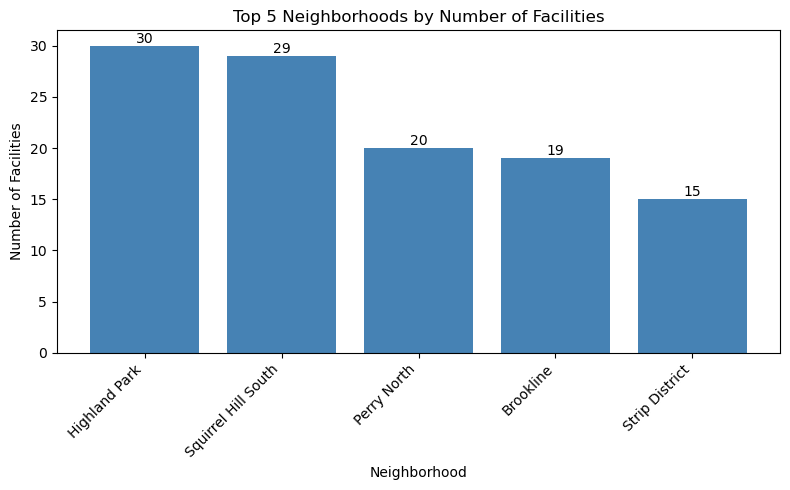

In [5]:
plt.figure(figsize=(8, 5))
plt.bar(top5["Neighborhood"], top5["Facility Count"], color="steelblue")
for i, v in enumerate(top5["Facility Count"]):
    plt.text(i, v, str(v), ha="center", va="bottom")
plt.title("Top 5 Neighborhoods by Number of Facilities")
plt.xlabel("Neighborhood")
plt.ylabel("Number of Facilities")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Above is a graph that displays the top 5 Pittsburgh neighborhoods with the highest facility counts. This gives a visual representation of each neighborhood, including how close Highland Park's and Squirrel Hill South's facilitiy counts are.